[1] DNA sequence downloaded successfully from NCBI.
    Source DNA sequence length: 2000 nucleotides (bp).

[Exercise 1: Numerical Calculations]


,Sample,Length (bp),MW (kDa),Distance (cm),Rf Value
0,S1,978,605.89,2.84,0.284
1,S2,331,205.46,4.62,0.462
2,S3,1902,1176.55,1.74,0.174
3,S4,997,617.43,2.80,0.280
4,S5,454,281.56,4.10,0.410
5,S6,476,294.31,4.03,0.403
6,S7,1815,1123.64,1.82,0.182
7,S8,1842,1139.62,1.79,0.179
8,S9,543,336.90,3.81,0.381
9,S10,1997,1235.26,1.66,0.166


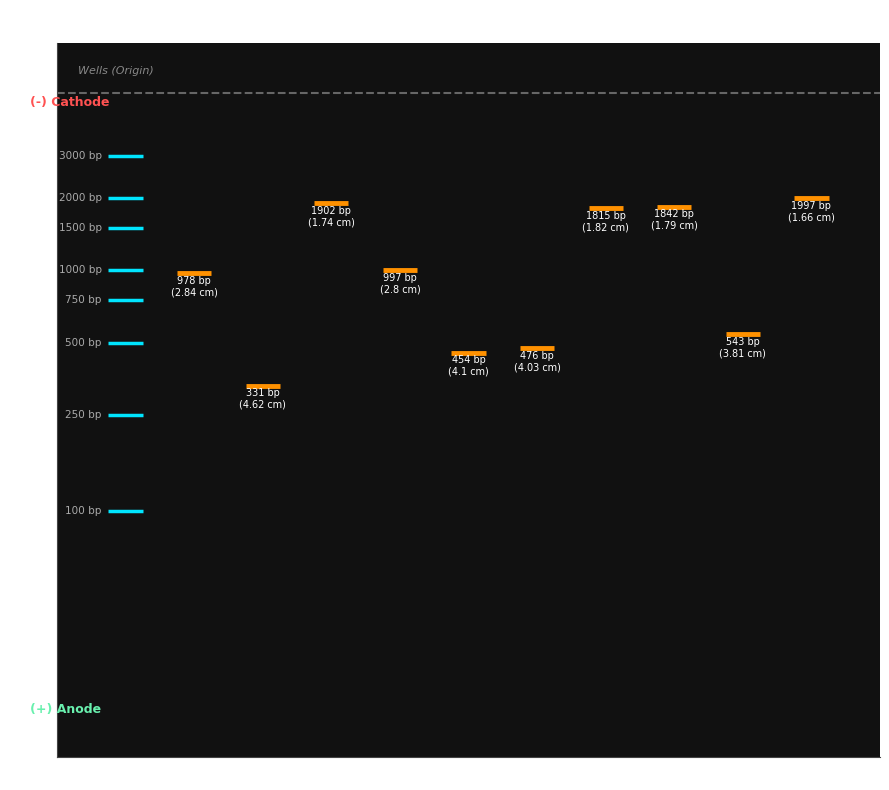

In [5]:
import urllib.request
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ncbi_accession = "NC_000011.10"
start_coord = 5225000
end_coord = 5227000
url = f"https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id={ncbi_accession}&seq_start={start_coord}&seq_stop={end_coord}&rettype=fasta&retmode=text"

try:
    with urllib.request.urlopen(url) as response:
        fasta_text = response.read().decode('utf-8')
    lines = fasta_text.strip().split('\n')
    dna_sequence = ''.join(lines[1:]).upper()
    print("[1] DNA sequence downloaded successfully from NCBI.")
except Exception as e:
    print(f"[1] Direct connection failed ({e}). Using generated sequence:")
    dna_sequence = "ATGGTGCACCTGACTCCTGAGGAGAAGTCTGCCGTTACTGCCCTGTGGGGCAAGGTGAACGTGGATGAAGTTGGTGGTGAGGCCCTGGGCAGGCTGCTGG" * 18

dna_sequence = dna_sequence[:2000]
total_length = len(dna_sequence)
print(f"    Source DNA sequence length: {total_length} nucleotides (bp).\n")

num_samples = 10
samples = []  
for _ in range(num_samples):
    sample_len = random.randint(100, min(total_length, 3000))
    start_pos = random.randint(0, total_length - sample_len)
    fragment = dna_sequence[start_pos : start_pos + sample_len]
    samples.append(fragment)

MW_BASES = {'A': 313.21, 'T': 304.20, 'C': 289.18, 'G': 329.21}
gel_length_cm = 10.0

calc_results = []
for idx, frag in enumerate(samples, 1):
    flen = len(frag)
    nA = frag.count('A')
    nT = frag.count('T')
    nC = frag.count('C')
    nG = frag.count('G')
    
    mw_da = (nA * MW_BASES['A'] + nT * MW_BASES['T'] + nC * MW_BASES['C'] + nG * MW_BASES['G']) * 2
    mw_kda = mw_da / 1000.0
    
    dist_cm = max(0.8, min(14.2 - 3.8 * np.log10(flen), 9.2))
    rf = dist_cm / gel_length_cm
    
    calc_results.append({
        'Sample': f'S{idx}',
        'Length (bp)': flen,
        'MW (kDa)': round(mw_kda, 2),
        'Distance (cm)': round(dist_cm, 2),
        'Rf Value': round(rf, 3)
    })

df_samples = pd.DataFrame(calc_results)
print("[Exercise 1: Numerical Calculations]")
display(df_samples)

fig, ax = plt.subplots(figsize=(9, 8))
ax.set_facecolor('#111111')

ax.axhline(0, color='#666666', linestyle='--', linewidth=1.5)
ax.text(0.3, -0.3, "Wells (Origin)", color='#888888', fontsize=8, style='italic')

ladder_bp = [3000, 2000, 1500, 1000, 750, 500, 250, 100]
for bp in ladder_bp:
    d = max(0.8, min(14.2 - 3.8 * np.log10(bp), 9.2))
    ax.hlines(d, 0.75, 1.25, color='#00e5ff', linewidth=2.5)
    ax.text(0.65, d, f"{bp} bp", color='#aaaaaa', fontsize=7.5, va='center', ha='right')

for row in calc_results:
    lane_idx = int(row['Sample'].replace('S', '')) + 1
    d = row['Distance (cm)']
    ax.hlines(d, lane_idx - 0.25, lane_idx + 0.25, color='#ff9100', linewidth=3.5)
    ax.text(lane_idx, d + 0.35, f"{row['Length (bp)']} bp\n({row['Distance (cm)']} cm)",
            color='white', fontsize=7, ha='center')

ax.set_ylim(10.5, -0.8)
ax.set_xlim(0, 12)
ax.set_xticks(range(1, 12))
ax.set_xticklabels(['Ladder'] + [f'S{i}' for i in range(1, 11)], color='white', fontsize=9)
ax.set_ylabel("Migration Distance (cm)", color='white', fontsize=10)
ax.tick_params(colors='white')

ax.text(-0.4, 0.2, "(-) Cathode", color='#ff5252', fontsize=9, fontweight='bold')
ax.text(-0.4, 9.8, "(+) Anode", color='#69f0ae', fontsize=9, fontweight='bold')

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#444444')
ax.spines['bottom'].set_color('#444444')

plt.title("Agarose Gel Electrophoresis Simulation", color='white', pad=15)
plt.tight_layout()
plt.show()

In [6]:
import itertools
import urllib.request
import pandas as pd

ncbi_accession = "NC_000011.10"
start_coord = 5225000
end_coord = 5227000
url = f"https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id={ncbi_accession}&seq_start={start_coord}&seq_stop={end_coord}&rettype=fasta&retmode=text"

try:
    with urllib.request.urlopen(url) as response:
        fasta_text = response.read().decode('utf-8')
    lines = fasta_text.strip().split('\n')
    dna_seq = ''.join(lines[1:]).upper()
except Exception:
    dna_seq = "ATGGTGCACCTGACTCCTGAGGAGAAGTCTGCCGTTACTGCCCTGTGGGGCAAGGTGAACGTGGATGAAGTTGGTGGTGAGGCCCTGGGCAGGCTGCTGG" * 15

dna_seq = dna_seq[:1800]
print(f"Target sequence loaded: {len(dna_seq)} nucleotides.\n")

nucleotides = ['A', 'C', 'G', 'T']
detected_repeats = []

for motif_len in range(3, 7):
    all_motifs = [''.join(p) for p in itertools.product(nucleotides, repeat=motif_len)]
    
    for motif in all_motifs:
        min_k = max(2, (6 + motif_len - 1) // motif_len)
        max_k = 10 // motif_len
        
        for k in range(min_k, max_k + 1):
            pattern = motif * k
            pattern_len = len(pattern)
            
            start_pos = 0
            while True:
                found_idx = dna_seq.find(pattern, start_pos)
                if found_idx == -1:
                    break
                
                detected_repeats.append({
                    'Start Position': found_idx,
                    'End Position': found_idx + pattern_len - 1,
                    'Base Motif': motif,
                    'Motif Length': motif_len,
                    'Repeat Count (k)': k,
                    'Total Length': pattern_len,
                    'Repeated Sequence': pattern
                })
                start_pos = found_idx + 1


df_repeats = pd.DataFrame(detected_repeats)

if not df_repeats.empty:
    df_repeats = df_repeats.drop_duplicates(subset=['Start Position', 'Repeated Sequence'])
    df_repeats = df_repeats.sort_values(by='Start Position').reset_index(drop=True)
    print(f"Detected {len(df_repeats)} repeated segments between 6 and 10 letters:")
    display(df_repeats.head(25))
else:
    print("No matching repetitions detected within the specified length range.")

Target sequence loaded: 1800 nucleotides.

Detected 55 repeated segments between 6 and 10 letters:


,Start Position,End Position,Base Motif,Motif Length,Repeat Count (k),Total Length,Repeated Sequence
0,10,15,ACA,3,2,6,ACAACA
1,43,48,GAG,3,2,6,GAGGAG
2,71,78,GGAA,4,2,8,GGAAGGAA
3,93,98,GGT,3,2,6,GGTGGT
4,329,334,CTT,3,2,6,CTTCTT
5,446,451,AAT,3,2,6,AATAAT
6,459,464,CAT,3,2,6,CATCAT
7,473,480,AAAT,4,2,8,AAATAAAT
8,482,487,TTT,3,2,6,TTTTTT
9,486,491,TTA,3,2,6,TTATTA
